<a href="https://colab.research.google.com/github/saichandanss2190/ITA0615-Machine-Learning-192312190-/blob/main/Exp_17.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Set random seed for reproducibility
np.random.seed(42)
num_samples = 1000

# Generating synthetic mobile specifications
ram = np.random.randint(512, 6000, size=num_samples)  # in MB
battery_power = np.random.randint(500, 5000, size=num_samples) # in mAh
int_memory = np.random.randint(4, 256, size=num_samples) # in GB
pixel_height = np.random.randint(0, 1960, size=num_samples)
pixel_width = np.random.randint(400, 2500, size=num_samples)
fc = np.random.randint(0, 20, size=num_samples) # Front camera megapixels

# Create a simple decision logic for price_range class mapping (0 to 3)
# Based on weighted specifications
score = (ram * 0.6) + (battery_power * 0.2) + (int_memory * 0.1) + ((pixel_height * pixel_width) / 200000 * 0.1)

# Binning scores into 4 distinct price ranges
quantiles = np.percentile(score, [25, 50, 75])
price_range = np.digitize(score, quantiles)

# Build DataFrame
df = pd.DataFrame({
    'battery_power': battery_power,
    'front_camera_mp': fc,
    'int_memory_gb': int_memory,
    'pixel_height': pixel_height,
    'pixel_width': pixel_width,
    'ram_mb': ram,
    'price_range': price_range
})

display(df.head())
print(f"Dataset shape: {df.shape}")

,battery_power,front_camera_mp,int_memory_gb,pixel_height,pixel_width,ram_mb,price_range
0,2497,17,58,1021,1351,1372,0
1,4187,5,211,644,2405,5902,3
2,2651,4,109,226,2416,5738,3
3,4518,12,193,700,2278,5703,3
4,3610,18,161,1499,1596,4284,2


Dataset shape: (1000, 7)


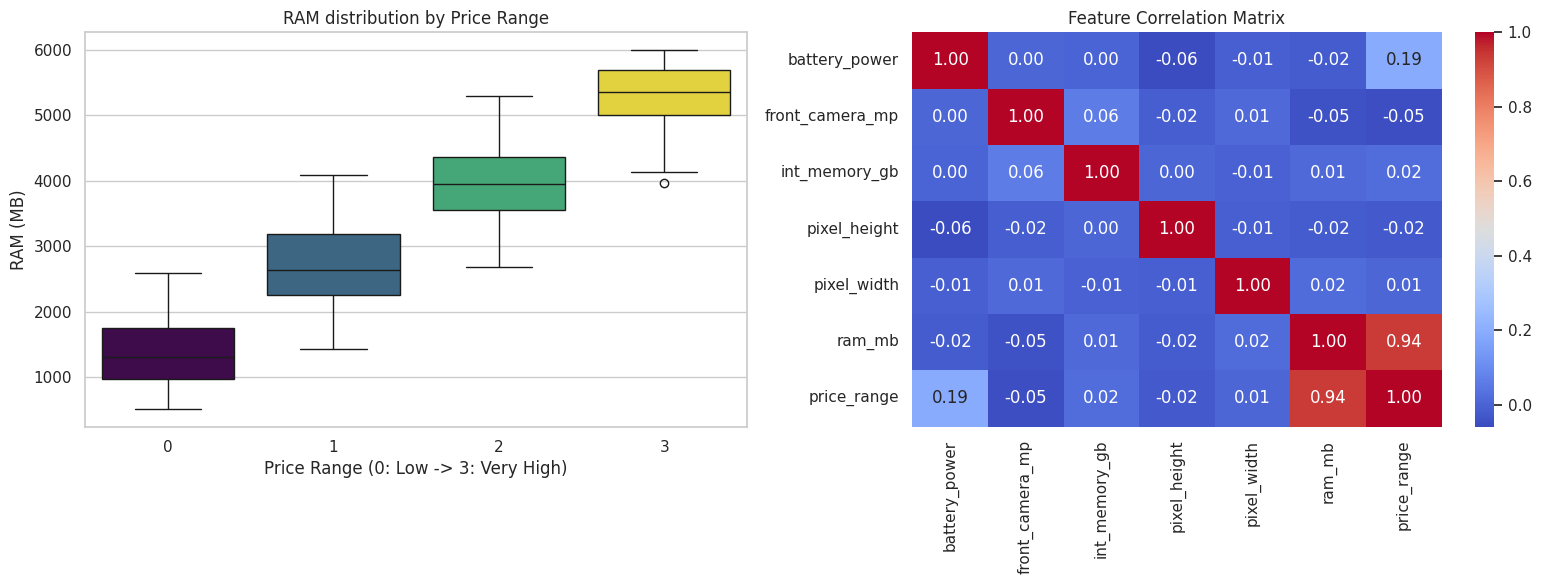

In [2]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# RAM vs Price Range
sns.boxplot(ax=axes[0], x='price_range', y='ram_mb', data=df, palette='viridis', hue='price_range', legend=False)
axes[0].set_title('RAM distribution by Price Range')
axes[0].set_xlabel('Price Range (0: Low -> 3: Very High)')
axes[0].set_ylabel('RAM (MB)')

# Feature Correlation Heatmap
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', ax=axes[1])
axes[1].set_title('Feature Correlation Matrix')

plt.tight_layout()
plt.show()

  Random Forest Model Accuracy: 92.00%
                precision    recall  f1-score   support

      Low Cost       0.95      0.98      0.97        63
   Medium Cost       0.93      0.87      0.90        62
     High Cost       0.86      0.89      0.88        63
Very High Cost       0.94      0.94      0.94        62

      accuracy                           0.92       250
     macro avg       0.92      0.92      0.92       250
  weighted avg       0.92      0.92      0.92       250



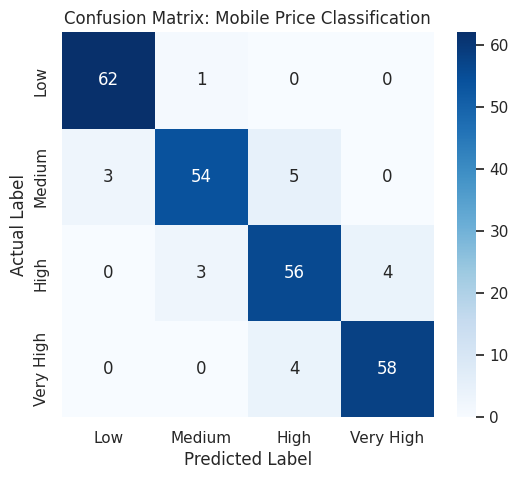

In [3]:
# Split data into features and target
X = df.drop('price_range', axis=1)
y = df['price_range']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# Train Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Predictions
y_pred = rf_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

# Presentable Performance Output
print("="*55)
print(f"  Random Forest Model Accuracy: {accuracy:.2%}")
print("="*55)
print(classification_report(y_test, y_pred, target_names=['Low Cost', 'Medium Cost', 'High Cost', 'Very High Cost']))

# Confusion Matrix Visualization
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Low', 'Medium', 'High', 'Very High'],
            yticklabels=['Low', 'Medium', 'High', 'Very High'])
plt.title('Confusion Matrix: Mobile Price Classification')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()